# Minimal Transformer Attention Demo for Beginners

This notebook uses very little code to explain the main idea of a transformer:

> A transformer understands a word by checking which other words are important for that word.

We will compare:

```text
the movie was good
the movie was not good
```

The key class question is: why does `not` change the meaning of `good`?

## 1. Big Picture

A full transformer has many parts, but beginners should first understand this flow:

```text
Sentence -> Tokens -> Attention -> Prediction
```

In this minimal demo, we will focus only on the idea of **attention**.

Attention answers:

```text
Which word should this word listen to?
```

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Tokenization

Tokenization means splitting a sentence into smaller pieces called **tokens**.

For this beginner example, each word is one token.

In [2]:
sentence = "the movie was not good"
tokens = sentence.split()

tokens

['the', 'movie', 'was', 'not', 'good']

## 3. Simple Attention Table

A real transformer learns attention weights during training.

For teaching, we will create a tiny attention table manually.

Meaning:

- Rows = the word that is trying to understand itself.
- Columns = the word it is listening to.
- Bigger number = more attention.

Here, we want `good` to pay attention to `not`.

In [3]:
attention = pd.DataFrame(
    [
        [0.70, 0.10, 0.10, 0.05, 0.05],  # the
        [0.10, 0.70, 0.10, 0.05, 0.05],  # movie
        [0.10, 0.10, 0.70, 0.05, 0.05],  # was
        [0.05, 0.05, 0.10, 0.75, 0.05],  # not
        [0.05, 0.10, 0.05, 0.65, 0.15],  # good listens to not
    ],
    index=tokens,
    columns=tokens,
)

attention

,the,movie,was,not,good
the,0.70,0.10,0.10,0.05,0.05
movie,0.10,0.70,0.10,0.05,0.05
was,0.10,0.10,0.70,0.05,0.05
not,0.05,0.05,0.10,0.75,0.05
good,0.05,0.10,0.05,0.65,0.15


## 4. Visualize Attention

The heatmap makes the attention idea easy to explain on screen.

Darker color means stronger attention.

Students should notice that `good` gives high attention to `not`.

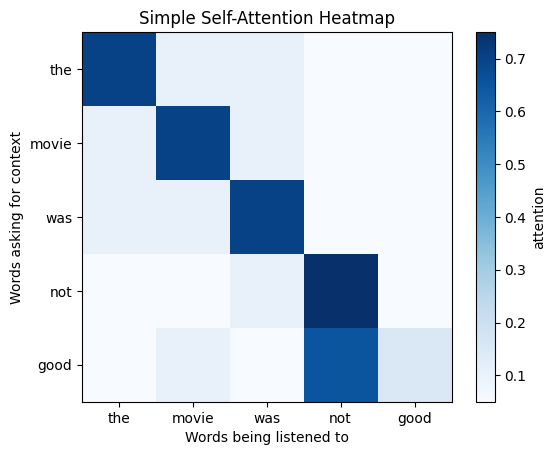

In [4]:
plt.imshow(attention, cmap="Blues")
plt.xticks(range(len(tokens)), tokens)
plt.yticks(range(len(tokens)), tokens)
plt.colorbar(label="attention")
plt.title("Simple Self-Attention Heatmap")
plt.xlabel("Words being listened to")
plt.ylabel("Words asking for context")
plt.show()

## 5. Tiny Prediction Logic

Now we make the smallest possible sentiment rule:

- If the sentence has `good`, it is positive.
- If the sentence has `not good`, it becomes negative.

This is not a real trained transformer. It is a simple classroom rule to show why attention to `not` matters.

In [5]:
if "not" in tokens and "good" in tokens:
    prediction = "Negative"
elif "good" in tokens:
    prediction = "Positive"
else:
    prediction = "Neutral"

print("Sentence:", sentence)
print("Prediction:", prediction)

Sentence: the movie was not good
Prediction: Negative


## 6. Compare Two Sentences

Run this cell to show the class how one word changes the result.

In [6]:
examples = ["the movie was good", "the movie was not good"]

for text in examples:
    words = text.split()
    if "not" in words and "good" in words:
        label = "Negative"
    else:
        label = "Positive"
    print(text, "->", label)

the movie was good -> Positive
the movie was not good -> Negative


## 7. Built-in Transformer Block with PyTorch

So far, we manually showed attention using a table.

Now we use a real built-in transformer layer from PyTorch:

```python
nn.TransformerEncoderLayer
```

This layer already contains the main transformer logic:

```text
self-attention -> feed forward network -> normalization
```

We are not training it here. We only show how a sentence goes inside a transformer block and comes out as context-aware vectors.

In [ ]:
import torch
from torch import nn

word_to_id = {word: number for number, word in enumerate(set(tokens))}
input_ids = torch.tensor([[word_to_id[word] for word in tokens]])

embedding = nn.Embedding(num_embeddings=len(word_to_id), embedding_dim=8)
transformer_block = nn.TransformerEncoderLayer(d_model=8, nhead=2, batch_first=True)

embedded_tokens = embedding(input_ids)
transformer_output = transformer_block(embedded_tokens)

print("Input token IDs shape:", input_ids.shape)
print("Embedding shape:", embedded_tokens.shape)
print("Transformer output shape:", transformer_output.shape)

## 8. Optional: Real Pretrained Transformer in Colab

The PyTorch layer above shows the built-in architecture block.

If you want a real pretrained transformer for sentiment prediction, run the next cell in Google Colab.

It uses Hugging Face `pipeline`, which downloads a small pretrained sentiment model.

In [ ]:
# In Google Colab, run this install line first if needed:
# !pip install -q transformers

import importlib.util

if importlib.util.find_spec("transformers") is None:
    print("transformers is not installed. In Colab, run: !pip install -q transformers")
else:
    transformers = __import__("transformers")
    classifier = transformers.pipeline("sentiment-analysis")
    result = classifier([
        "the movie was good",
        "the movie was not good"
    ])
    result

## 9. Final  Takeaway

A transformer does not understand `good` alone.

It checks the context around `good`.

In this sentence:

```text
the movie was not good
```

The important context word is:

```text
not
```

So the meaning changes from positive to negative.

The manual attention table shows the idea. The PyTorch transformer block shows how we use built-in transformer logic in real code.

Simple explanation for students:

> Self-attention helps each word look at the other words that change its meaning.